# Milestone 3: EDA, Baseline Modeling, and Pipeline Development

**Project #63**

**Group Members:** Matlin Gilman and Brianna Grissom


## Table of Contents

1. **Problem Introduction & Research Question**
2. **Data Description**
3. **Imports & Data Loading**
4. **Extended Exploratory Data Analysis**
   1. Keyword Deep-Dive
   2. Note Structure & Section Analysis
   3. Note Length Distribution
   4. EDA Summary & Implications for Modeling
5. **Baseline Model 1 &mdash; TF-IDF + Random Forest**
   1. Load & Prepare the MIMIC-III Labeled SDOH Dataset
   2. Train / Validation Split
   3. Pipeline Creation & Hyperparameter Tuning
   4. Evaluate on Labeled Validation Set
   5. Preprocessing: Split SMI Discharge Notes into Sentences
   6. Inference on the MIMIC-IV SMI Cohort
6. **Baseline Model 2 &mdash; Word2Vec + MLP Neural Network**
   1. Train Custom Clinical Word Embeddings
   2. Sentence-to-Vector Function
   3. Train MLP Classifier & Evaluate
      - Tune the Classification Threshold on Validation
   4. Inference on the MIMIC-IV SMI Cohort
   5. View Sentences Flagged as Housing Mentions
7. **Results Comparison & Interpretation**
8. **Final Model Pipeline**
9. **Future Directions & Next Steps**


# Data Description 

| Source | What It Contains |
|---|---|
| **MIMIC-IV** (structured tables) | A large, publicly available critical care database covering ~546,000 hospital admissions at Beth Israel Deaconess Medical Center (Boston) between 2008 and 2019. We use three tables: `admissions.csv` (one row per hospital stay, with race, insurance, discharge disposition, and timestamps), `patients.csv` (one row per patient, with gender and de-identified age), and `diagnoses_icd.csv` (one row per diagnosis per admission, with ICD-9 and ICD-10 codes ranked by clinical priority via `seq_num`). Access requires PhysioNet credentialing and a data use agreement. |
| **MIMIC-IV-Note** (clinical text) | A companion release to MIMIC-IV containing ~331,000 deidentified free-text discharge summaries written by clinicians. Notes are split across 7 CSV files and linked to MIMIC-IV admissions by `hadm_id` (the hospital admission ID). This is the corpus we search for housing mentions. Coverage is partial — not every MIMIC-IV admission has a corresponding note, for reasons related to the data release process rather than clinical practice. |
| **MIMIC-III-Labeled-SDOH** | A separate, smaller dataset of 1,800 clinical sentences from the earlier MIMIC-III release, hand-labeled by human annotators for the presence of social determinants of health (housing, food insecurity, substance use, etc.) and whether each mention is *adverse* (e.g., homelessness) or non-adverse. We use it solely as an independent validation set to measure the precision and recall of our keyword search before applying it to MIMIC-IV-Note. |


# Problem Introduction

Research Question:
> **How consistently is housing actually mentioned in discharge summaries for patients hospitalized with serious mental illness?**


In Milestone 2, we built an admissions-level dataset from MIMIC-IV and MIMIC-IV-Note, which cover ~546,000 hospital admissions at Beth Israel Deaconess Medical Center (Boston) between 2008 and 2019. We filtered to the 3,808 admissions where the patient's primary diagnosis was a serious mental illness (SMI), excluding non-community discharges.

We validated a 20-keyword housing search against the hand-labeled MIMIC-III SDOH dataset, achieving a recall of 0.39. Applying the same search to our unlabeled SMI cohort found housing mentioned in 1,940 (50.95%) of discharge notes.

Key findings from our Milestone 2 EDA:
- Housing mention rates were higher for Black and Hispanic patients than for White patients
- Schizophrenia patients had substantially higher housing mention rates than those with Bipolar Disorder or Major Depressive Disorder
- Patients on Medicare or Medicaid had higher mention rates than those with private insurance
- Notes that mention housing tend to be longer

Because the keyword search has a recall ceiling of 0.39 — missing more than half of true housing mentions — and cannot capture phrasings outside the fixed keyword list, Milestone 2 results represent a lower bound on true documentation rates.

**Goal for this milestone: train sentence-level classifiers on the labeled MIMIC-III SDOH dataset to detect housing mentions, apply them to our SMI cohort, and compare detection rates and subgroup patterns against the keyword baseline.**


# Imports & Data Loading

Load in the SMI dataset.

In [81]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


In [ ]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    df = pd.read_csv('/content/drive/MyDrive/AC209b-project-data/df_final.csv')
else:
    df = pd.read_csv('data/df_final.csv')

# Extended Exploratory Data Analysis

Milestone 2 established the keyword-search baseline and broke mention rates down by demographics. Here we dig deeper with the explicit goal of **informing our Milestone 3 modeling choices**. Specifically, we investigate:

1. **Which keywords actually trigger** &mdash; to see how much the regex relies on a few terms.
2. **Where in the discharge note housing mentions live** &mdash; to decide whether to model at the sentence, section, or note level.
3. **How long notes are** &mdash; to assess feasibility of transformer-based models with 512-token limits.

Each finding below is paired with a direct implication for our modeling choices; these are consolidated in the *EDA Summary* at the end of this section.


### 1. Keyword Deep-Dive
Let's see which specific housing-related keywords appear most frequently in our SMI cohort's discharge notes.

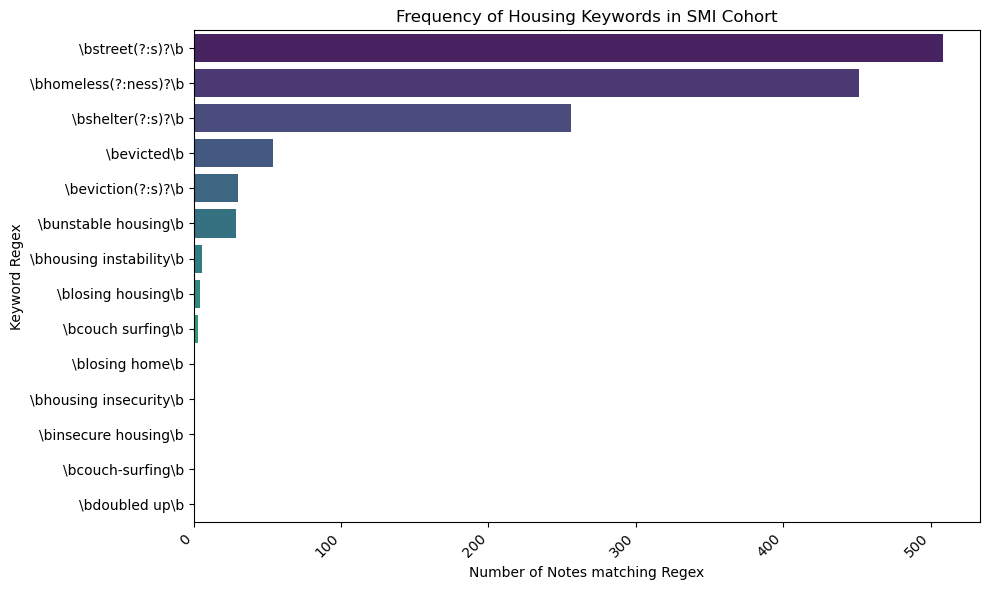

In [63]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# We will reuse the HOUSING_REGEX list from milestone 2
HOUSING_REGEX = [
    r'\bhomeless(?:ness)?\b',
    r'\bshelter(?:s)?\b',
    r'\bencampment(?:s)?\b',
    r'\buncamp(?:ed)?\b',
    r'\bunsheltered\b',
    r'\bstreet(?:s)?\b',
    r'\bcouch surfing\b',
    r'\bcouch-surfing\b',
    r'\bdoubled up\b',
    r'\bdoubled-up\b',
    r'\bevicted\b',
    r'\beviction(?:s)?\b',
    r'\bwithout a home\b',
    r'\bno fixed(?: abode| address)?\b',
    r'\blosing housing\b',
    r'\blose housing\b',
    r'\blosing home\b',
    r'\blose home\b',
    r'\bhousing instability\b',
    r'\bhousing unstable\b',
    r'\bunstable housing\b',
    r'\binsecure housing\b',
    r'\bhousing insecurity\b'
]

compiled_regexes = {pat: re.compile(pat, re.IGNORECASE) for pat in HOUSING_REGEX}

keyword_counts = Counter()
for text in df['discharge_text'].dropna():
    for pat_str, regex in compiled_regexes.items():
        if regex.search(text):
            keyword_counts[pat_str] += 1

# Plot top keywords
key_df = pd.DataFrame(keyword_counts.most_common(), columns=['Keyword Regex', 'Count'])

plt.figure(figsize=(10, 6))
sns.barplot(data=key_df, y='Keyword Regex', x='Count', palette='viridis')
plt.title('Frequency of Housing Keywords in SMI Cohort')
plt.xlabel('Number of Notes matching Regex')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


We find that housing keyword matches are heavily concentrated on just three terms — homeless, street, and shelter — while most of the remaining 20 keywords never appear at all (only 9 of 23 fire in the entire cohort). This skew suggests a limitation of the keyword search approach: the keyword list captures a narrow slice of the language clinicians actually use to describe housing, and any mention phrased differently could go uncounted. It also means the 50.95% mention rate from Milestone 2 is driven largely by these three terms, not by broad coverage. This motivates training a sentence-level classifier that can generalize to the full range of clinical phrasing rather than matching against a fixed list.

### 2. Note Structure & Section Analysis

Which specific sections from the discharge notes contain housing mentions via the keyword search? This will help us with our feature engineering step by making sure to include sections with housing mentions and pruning those that do not, feeding less noise into the models.

In [91]:
from collections import defaultdict

def normalize_header(header):
    """Canonicalize a section header: strip 'None' prefix artifacts and collapse whitespace."""
    cleaned = re.sub(r'^\s*None\s*', '', header)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned

all_mention_headers = Counter()          # lowercase normalized key -> count
display_variants    = defaultdict(Counter)  # lowercase key -> Counter of original forms

for text in df[df['housing_mention'] == 'yes']['discharge_text'].dropna():
    # Only keep the contexts around mention matches to figure out which headers surround them.
    # Split the note by headers and check which chunk contains the keywords.
    chunks = re.split(r'\n([A-Z][a-zA-Z\s/]+):', text)
    # chunks alternates: [text_before_first_header, header1, text1, header2, text2, ...]
    if len(chunks) > 1:
        for i in range(1, len(chunks), 2):
            header = chunks[i].strip()
            section_text = chunks[i + 1]

            # Check if this section contains a housing mention
            for regex in compiled_regexes.values():
                if regex.search(section_text):
                    display_form = normalize_header(header)     # whitespace cleaned, case preserved
                    key          = display_form.lower()         # case-insensitive grouping key
                    all_mention_headers[key] += 1
                    display_variants[key][display_form] += 1
                    break

# For each normalized key, display the most common original-case form so "Social History"
# is shown instead of "SOCIAL HISTORY" (since it is the more frequent variant).
rows = []
for key, count in all_mention_headers.most_common(20):
    pretty = display_variants[key].most_common(1)[0][0]
    rows.append((pretty, count))

top_headers = pd.DataFrame(rows, columns=['Section Header', 'Housing Mentions Found'])
print("Top Document Sections Containing Housing Mentions:")
display(top_headers)


Top Document Sections Containing Housing Mentions:


,Section Header,Housing Mentions Found
0,History of Present Illness,373
1,Brief Hospital Course,152
2,Social History,97
3,Axis IV,58
4,Pertinent Results,39
5,Discharge Diagnosis,28
6,PSYCHIATRIC,24
7,INFORMED CONSENT,22
8,RISK ASSESSMENT,21
9,Chief Complaint,21


"History of Present Illness" contains most of the housing mentions via the keyword search, followed by "Brief Hospital Course".

### 3. Note Length Distribution
Let's visualize the token counts (approximated by word counts) to see how many discharge notes exceed the typical 512-token ClinicalBERT limit.

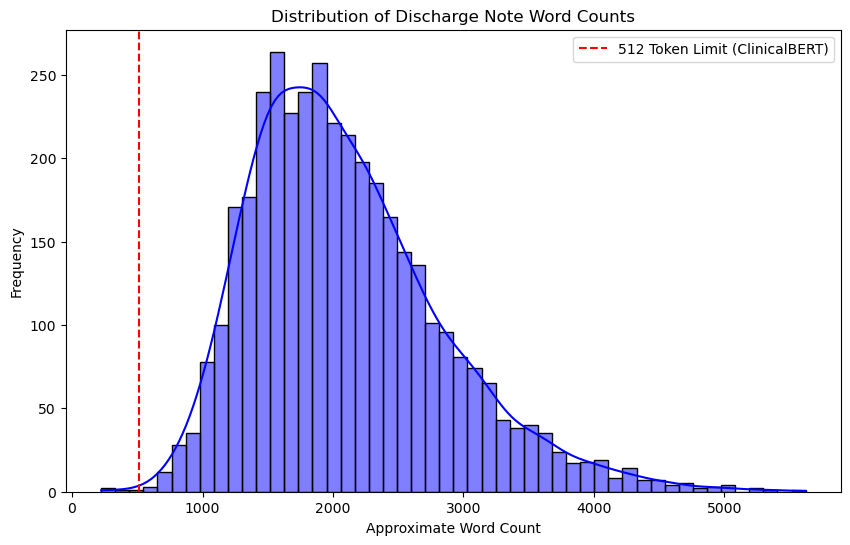

Notes exceeding 512 words: 3804 / 3808 (99.89%)


In [66]:
df['word_count'] = df['discharge_text'].fillna('').apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], bins=50, kde=True, color='blue')
plt.axvline(x=512, color='red', linestyle='--', label='512 Token Limit (ClinicalBERT)')
plt.title('Distribution of Discharge Note Word Counts')
plt.xlabel('Approximate Word Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

exceeds_512 = (df['word_count'] > 512).sum()
total_notes = len(df)
print(f"Notes exceeding 512 words: {exceeds_512} / {total_notes} ({exceeds_512/total_notes*100:.2f}%)")


Since most notes likely exceed the 512 token limit, this justifies the need to split up discharge notes into smaller sections (like sentences) when feeding them into our ClinicalBERT model in the next milestone.

## EDA Summary & Implications for Modeling

| Finding | Modeling implication |
|---------|----------------------|
| Only 9 of 23 housing keywords ever fire; `homeless`, `street`, `shelter` dominate | The regex has a fixed ceiling; a model must generalize to unseen phrasings &mdash; argues for **word-embedding or transformer** representations over pure bag-of-words. |
| Housing mentions cluster in narrative sections (*History of Present Illness*, *Brief Hospital Course*, *Social History* account for most of the matches) | Work at the **sentence level after stripping non-narrative sections** (labs, meds, physical exam) &mdash; see the preprocessing step in Baseline 1 §5. |
| Median note &gt; 2,000 words, far exceeding the 512-token BERT limit | Whole-note transformer inference is infeasible; we commit to **sentence-level inference with `max`-aggregation** to the admission level. |


# Baseline Modeling

## Goal

Replace the Milestone 2 keyword regex (recall = 0.39 on labeled data) with a sentence-level classifier that **generalizes** to phrasings the regex misses. Both baselines we use are trained on `MIMIC-III-Labeled-SDOH` (1,800 hand-labeled sentences, 80/20 train/val stratified split) and applied to the `MIMIC-IV` SMI cohort (3,808 notes) with the full discharge notes split into sentences. Notes are flagged as having a housing mention if at least one sentence is flagged.
## Model choices and justification

| Baseline | Representation | Classifier | Why this model |
|----------|----------------|------------|----------------|
| **1. TF-IDF + Random Forest** | Unigrams + bigrams, 5k features, English stopwords | Random Forest (`class_weight='balanced'`, `GridSearchCV` over `n_estimators` &times; `max_depth`) | Fast, interpretable sanity check that captures non-linear interactions between n-grams. Sets a lower bound on what a lexical model can do. |
| **2. Word2Vec + MLP** | Mean-pooled 100-dim embeddings trained on our MIMIC-IV SMI corpus | MLP (hidden layers 100 &rarr; 50, `early_stopping=True`) | Captures semantic similarity so synonyms (e.g. `unhoused`, `shelter`, `homeless`) land near each other in vector space. Simplest neural baseline covered in AC209B and a direct stepping-stone to the final ClinicalBERT model. |


## Metrics

- **Recall** &mdash; Our primary goal is to beat the recall of 0.39 from the housing keyword search on the full `MIMIC-III-Labeled-SDOH` dataset. We hope to get a higher recall the validation set of `MIMIC-III-Labeled-SDOH`.
- **F1** &mdash; balances recall with precision; also used to tune the MLP decision threshold on the validation set (§3b of Baseline 2).
- **Note-level housing detection rate on the SMI cohort** &mdash; for comparison against the 50.95% MS2 baseline from the keyword search.
- **Agreement matrices** &mdash; cross-tabulate each ML model against the keyword regex on the SMI cohort to show where the model adds or removes signal.

---

## Baseline 1: TF-IDF + Random Forest


### 1. Load & Prepare the MIMIC-III Labeled SDOH Dataset

In [67]:
import pandas as pd
import numpy as np

if IN_COLAB:
    round1 = pd.read_csv('/content/drive/MyDrive/AC209b-project-data/SyntheticSentences_Round1.csv')
    round2 = pd.read_csv('/content/drive/MyDrive/AC209b-project-data/SyntheticSentences_Round2.csv')
else:
    round1 = pd.read_csv('data/SyntheticSentences_Round1.csv')
    round2 = pd.read_csv('data/SyntheticSentences_Round2.csv')

labeled_sdoh = pd.concat([round1, round2], ignore_index=True)

# Clean and extract the target
labeled_sdoh = labeled_sdoh.dropna(subset=['text', 'label']).copy()
labeled_sdoh['housing_target'] = labeled_sdoh['label'].astype(str).str.strip().str.upper().eq('HOUSING').astype(int)

X_labeled = labeled_sdoh['text']
y_labeled = labeled_sdoh['housing_target']

print(f"Labeled Dataset Shape: {labeled_sdoh.shape}")
print(f"Target Distribution:\n{y_labeled.value_counts(normalize=True)*100}")

Labeled Dataset Shape: (1800, 4)
Target Distribution:
housing_target
0    88.888889
1    11.111111
Name: proportion, dtype: float64


### 2. Train / Validation Split
We split the `MIMIC-III Labeled SDOH` dataset into 80% training and 20% validation, so only part of the dataset was used for training.

In [68]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_labeled, y_labeled, test_size=0.2, random_state=RANDOM_SEED, stratify=y_labeled
)
print(f"Training set: {len(X_train)} sentences")
print(f"Validation set: {len(X_val)} sentences")


Training set: 1440 sentences
Validation set: 360 sentences


### 3. Pipeline Creation & Hyperparameter Tuning
We construct a Pipeline to perform TF-IDF vectorization up to bigrams, followed by a Random Forest Classifier. `class_weight='balanced'` handles the positive class rarity. We use a grid search to find optimal values of the hyperparameters `classifier__n_estimators` and `classifier__max_depth`.

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Create a highly restrictive TF-IDF to avoid memory overloads, capturing bigrams
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')

# Initialize the classifier (using balanced since housing instances are the minority)
rf = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_SEED)

# Build pipeline
pipeline = Pipeline([
    ('tfidf', tfidf),
    ('classifier', rf)
])

# Define grid for hyperparameter tuning
# Kept relatively small for quick baseline turnaround
param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [None, 10, 20]
}

grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=3, 
    scoring='f1', 
    n_jobs=-1,
    verbose=1
)

print("Fitting the Baseline Model GridSearch...")
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"\nBest parameters found: {grid_search.best_params_}")


Fitting the Baseline Model GridSearch...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best parameters found: {'classifier__max_depth': None, 'classifier__n_estimators': 100}


### 4. Evaluate the Baseline
We want to beat the keyword search recall of 0.39 on the validation split.

--- Validation Classification Report ---

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       320
           1       1.00      0.80      0.89        40

    accuracy                           0.98       360
   macro avg       0.99      0.90      0.94       360
weighted avg       0.98      0.98      0.98       360



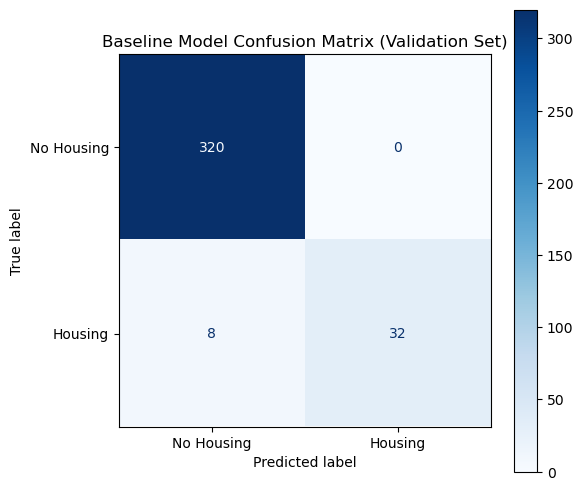

In [70]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_val)

print("--- Validation Classification Report ---\n")
print(classification_report(y_val, y_pred))

# Plot confusion matrix
cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title('Baseline Model Confusion Matrix (Validation Set)')
plt.show()


The TF-IDF Random Forest model did well on the `MIMIC-III Labeled SDOH` dataset achieving a recall of 0.80 on the sentences having a housing mention. This beats our goal of having a recall higher than 0.39 and mseets our expectations because we hoped for more sophisticated ML models to catch housing mentions better than a simple keyword search.

### 5. Preprocessing: Split SMI Discharge Notes into Sentences

Our model was trained on single-sentence inputs like:

> *"Patient recently moved into an apartment but is experiencing issues with pests such as bed bugs and roaches."*

but our inference data is full discharge notes (median ~2,000 words). A naive split on `\n` or `.` produces noise that looks nothing like the training distribution, containing censored information, headings, medication information, and more.

**We apply a two-stage filter:**

1. **Section-level.** Split each note on `Header:` delimiters. Drop sections whose content is known to be non-narrative: `Pertinent Results` (labs), `Discharge Medications`, `Physical Exam`, `Allergies`, `Followup Instructions`, and the top-of-note identifiers (`Name`, `Unit No`, `Admission Date`, etc.).
2. **Sentence-level.** Split remaining sections on sentence boundaries (`.!?` followed by whitespace + capital). Drop candidates that are (a) &lt; 25 characters / &lt; 5 words, (b) mostly non-alphabetic, (c) mostly uppercase, (d) contain lab tokens, (e) combine &ge;2 medication-order markers (dose, route, frequency), or (f) end in a colon.

The result is a `smi_sentences_df` whose sentences resemble the labeled training distribution much more closely than a naive split would.


In [ ]:
import re
import pandas as pd
from tqdm.auto import tqdm

# Section headers whose content is NOT narrative — skip these sections entirely
NON_NARRATIVE_HEADERS = {
    # Labs, imaging, vitals
    'pertinent results', 'pertinent labs', 'labs', 'admission labs',
    'discharge labs', 'labs on admission', 'labs on discharge',
    'imaging', 'studies', 'diagnostic studies', 'studies on admission',
    'physical exam', 'physical examination', 'exam', 'admission exam',
    'vitals', 'vital signs',

    # Medications
    'medications', 'medications on admission', 'discharge medications',
    'admission medications', 'home medications',

    # Identifiers / boilerplate
    'name', 'unit no', 'admission date', 'discharge date', 'date of birth',
    'sex', 'service', 'attending', 'allergies', 'facility',
    'discharge instructions', 'followup instructions', 'followup',
    'discharge disposition', 'major surgical or invasive procedure',
}

# Match "\n<HeaderWords>:" — splits the note into [preamble, h1, c1, h2, c2, ...]
HEADER_RE = re.compile(r'\n([A-Z][A-Za-z0-9/\s]{1,60}?):\s*')

# Patterns that indicate a line is lab values or a medication order
LAB_TOKEN_RE = re.compile(r'\b[A-Z]{2,}-[\d.]+')             # e.g. GLUCOSE-96, WBC-7.6
DOSE_RE      = re.compile(r'\b\d+(?:\.\d+)?\s?(?:mg|mcg|mL|ml|g)\b', re.IGNORECASE)
ROUTE_RE     = re.compile(r'\b(?:PO|IV|IM|SC|IH|SL|PR|PRN)\b')
FREQ_RE      = re.compile(r'\b(?:QHS|QAM|QPM|QID|BID|TID|Q[0-9]+H|QOD|QD)\b', re.IGNORECASE)

# Split on .!? followed by whitespace + a capital letter
SENT_SPLIT_RE = re.compile(r'(?<=[.!?])\s+(?=[A-Z])')


def is_narrative_sentence(s: str) -> bool:
    s = s.strip()
    s_core = s.replace('___', '').strip()   # ignore placeholder masks for length check
    if len(s_core) < 25 or len(s_core.split()) < 5:
        return False

    letters = sum(c.isalpha() for c in s_core)
    # Must be mostly alphabetic (filters lab / numeric lines)
    if letters / max(len(s_core), 1) < 0.6:
        return False
    # Mostly uppercase = a header or a lab heading, not prose
    if sum(c.isupper() for c in s_core) / max(letters, 1) > 0.4:
        return False

    if LAB_TOKEN_RE.search(s):
        return False
    # Medication lines combine doses, routes, and frequencies
    if len(DOSE_RE.findall(s)) + len(ROUTE_RE.findall(s)) + len(FREQ_RE.findall(s)) >= 2:
        return False
    # A trailing colon means it's a header, not a sentence
    if s.rstrip().rstrip('.!?').endswith(':'):
        return False

    return True


def note_to_sentences(note):
    """Split a discharge note into clean narrative sentences, section by section."""
    if not isinstance(note, str) or not note.strip():
        return []
    # parts = [preamble, header1, content1, header2, content2, ...]
    parts = HEADER_RE.split('\n' + note)
    if len(parts) < 3:
        return []

    sentences = []
    # Skip parts[0] (the preamble with Name: ___ / Unit No: ___ etc.)
    for i in range(1, len(parts), 2):
        header = parts[i].strip().lower()
        content = parts[i + 1] if i + 1 < len(parts) else ''
        if header in NON_NARRATIVE_HEADERS:
            continue
        # Collapse whitespace within a section so wrapped lines join back into one sentence,
        # then split the section independently so sentences don't run across section boundaries.
        content = re.sub(r'\s+', ' ', content).strip()
        if not content:
            continue
        for s in SENT_SPLIT_RE.split(content):
            if is_narrative_sentence(s):
                sentences.append(s.strip())
    return sentences


print("Extracting narrative sentences from SMI discharge notes...")
sentence_rows = []
for _, row in tqdm(df.iterrows(), total=len(df)):
    for s in note_to_sentences(row['discharge_text']):
        sentence_rows.append({'hadm_id': row['hadm_id'], 'sentence_text': s})

smi_sentences_df = pd.DataFrame(sentence_rows)
print(f"Extracted {len(smi_sentences_df)} narrative sentences from {len(df)} notes.")
print(f"Average sentences per note: {len(smi_sentences_df) / len(df):.1f}")
print("\nSample sentences:")
for s in smi_sentences_df['sentence_text'].sample(5, random_state=RANDOM_SEED):
    print(f"  - {s}")


### 6. Inference on the MIMIC-IV SMI Cohort
Finally, we apply our trained baseline model to our SMI discharge texts that were previously split up into sentences.

In [72]:
print("\nRunning inference on the SMI sentences...")
# Predict on the sentences
smi_sentences_df['housing_sent_pred'] = best_model.predict(smi_sentences_df['sentence_text'])

# Aggregate back to the admission level
# If ANY sentence in a hadm_id is predicted as 1, the whole note is 1
note_predictions = smi_sentences_df.groupby('hadm_id')['housing_sent_pred'].max().reset_index()
note_predictions.rename(columns={'housing_sent_pred': 'housing_ml_pred'}, inplace=True)

# Merge back to our main df
if 'housing_ml_pred' in df.columns:
    df.drop(columns=['housing_ml_pred'], inplace=True)

df = df.merge(note_predictions, on='hadm_id', how='left')
# Fill NA with 0 (for notes that had no valid sentences)
df['housing_ml_pred'] = df['housing_ml_pred'].fillna(0).astype(int)

ml_housing_rate = df['housing_ml_pred'].mean() * 100
regex_housing_rate = (df['housing_mention'] == 'yes').mean() * 100

print(f"\nHousing Detection Rate (Keyword/Regex Baseline): {regex_housing_rate:.2f}%")
print(f"Housing Detection Rate (TF-IDF + RF Baseline):   {ml_housing_rate:.2f}%")

# Cross-tabulate the regex baseline against the RF predictions on the SMI cohort
cross_tab_rf = pd.crosstab(
    df['housing_mention'].replace({'yes': 'Positive', 'no': 'Negative'}),
    df['housing_ml_pred'].replace({1: 'Positive', 0: 'Negative'}),
    rownames=['Regex Heuristic'],
    colnames=['TF-IDF + RF'],
)
print("\nAgreement Matrix (Regex vs TF-IDF + RF):")
display(cross_tab_rf)



Running inference on the SMI sentences...

Housing Detection Rate (Keyword/Regex Baseline): 50.95%
Housing Detection Rate (TF-IDF + RF Baseline):   1.16%

Agreement Matrix (Regex vs TF-IDF + RF):


TF-IDF + RF,Negative,Positive
Regex Heuristic,,
Negative,1867,1
Positive,1897,43


**Interpretation.** Despite a strong recall on the labeled validation set, the Random Forest flags only 1.16% of MIMIC-IV SMI notes as housing-positive &mdash; far below the MS2 keyword rate of 50.95%. The cross-tab shows near-total disagreement with the regex. Two root causes:

- **Vocabulary shift.** `MIMIC-III-Labeled-SDOH` is a set of cleanly written synthetic sentences, while MIMIC-IV discharge notes use heavy abbreviations (`h/o`, `w/r/t`), `___` placeholders from deidentification, and run-on clinical shorthand. TF-IDF features tuned to the former rarely fire on the latter.
- **Bag-of-words ignores semantics.** Phrases like `"lives with his mother"` or `"currently in a shelter"` may never have appeared in exactly that form in the training data, so the RF never learned to associate them with the housing class.

&rarr; Baseline 2 addresses the second issue by switching to word embeddings.


# Second Baseline: Word Embeddings (Word2Vec) + MLP Neural Network

Because TF-IDF relies on exact term frequencies, it fails to generalize when evaluating diverse clinical documents. Here, we train a custom Word2Vec model on `MIMIC-II-Labeled-SDOH` to learn the *semantic meaning* of words. We then convert sentences into mathematical vectors and feed them into a Multi-Layer Perceptron (MLP) Neural Network.

### 1. Train Custom Clinical Word Embeddings on SMI Discharge Notes
We use our SMI discharge notes split into sentences (already extracted above) to implicitly build rich, domain-specific continuous word representations.

In [73]:
from gensim.models import Word2Vec
from sklearn.neural_network import MLPClassifier
import numpy as np
import re
import random

if 'RANDOM_SEED' not in globals():
    RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Tokenizing corpus for Word2Vec training...")
# Very basic tokenizer looking for alphanumeric words
def basic_tokenize(text):
    return [w.lower() for w in re.findall(r'\b\w+\b', str(text))]

# We can actually use the sentences we already extracted in Step 5 previously!
# They are stored in smi_sentences_df['sentence_text']
w2v_corpus = [basic_tokenize(s) for s in smi_sentences_df['sentence_text']]

print(f"Training Word2Vec on {len(w2v_corpus)} clinical sentences...")
# Train Word2Vec (100 dimensions, window size 5, drop rare words < 3 occurrences)
w2v_model = Word2Vec(
    sentences=w2v_corpus,
    vector_size=100,
    window=5,
    min_count=3,
    workers=1,
    seed=RANDOM_SEED
)

print("Training finished! Let's see what the clinical model mathematically thinks is most similar to 'homeless':")
try:
    display(w2v_model.wv.most_similar('homeless', topn=5))
except:
    print("Word 'homeless' not in vocabulary enough times.")


Tokenizing corpus for Word2Vec training...
Training Word2Vec on 253610 clinical sentences...


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Training finished! Let's see what the clinical model mathematically thinks is most similar to 'homeless':


[('unemployed', 0.708335280418396),
 ('sober', 0.6192523241043091),
 ('incarcerated', 0.6152623295783997),
 ('employed', 0.6130220293998718),
 ('married', 0.6103243827819824)]

### 2. Convert Sentences to Vectors
Each sentence is converted to a fixed-length 100-dimensional vector by averaging the Word2Vec embeddings of its constituent words. We apply this to both the `MIMIC-III Labeled SDOH` training sentences and the SMI discharge note sentences used for inference.

In [74]:
def sentence_to_avg_vector(text, model, vector_size=100):
    words = basic_tokenize(text)
    word_vecs = []
    for w in words:
        if w in model.wv.key_to_index:
            word_vecs.append(model.wv[w])
    
    if len(word_vecs) == 0:
        return np.zeros(vector_size)
    
    return np.mean(word_vecs, axis=0)

# Apply to training, validation, and inference sets
print("Converting text strings to 100-dimensional semantic vectors...")
X_train_vec = np.array([sentence_to_avg_vector(text, w2v_model) for text in X_train])
X_val_vec = np.array([sentence_to_avg_vector(text, w2v_model) for text in X_val])

# We can reuse the inference sentences from step 5 above
X_smi_vec = np.array([sentence_to_avg_vector(text, w2v_model) for text in smi_sentences_df['sentence_text']])
print("Vectorization complete.")


Converting text strings to 100-dimensional semantic vectors...
Vectorization complete.


### 3. Train MLP Classifier & Evaluate
Now we train a standard Neural Network on `MIMIC-III-Labeled-SDOH` to map the continuous word embeddings to a binary variable for housing mention.

Training MLP Neural Network...
Training MLP Neural Network on balanced data...

--- Validation Classification Report (Word2Vec + MLP) ---

              precision    recall  f1-score   support

           0       0.97      0.96      0.97       320
           1       0.71      0.80      0.75        40

    accuracy                           0.94       360
   macro avg       0.84      0.88      0.86       360
weighted avg       0.95      0.94      0.94       360



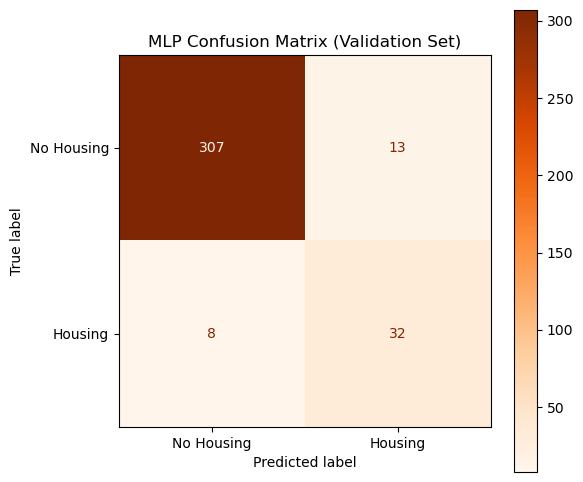

In [76]:
# Initialize the Multi-Layer Perceptron
# We add EarlyStopping so it doesn't overfit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
mlp = MLPClassifier(hidden_layer_sizes=(100, 50), 
                    max_iter=500, 
                    early_stopping=True, 
                    random_state=RANDOM_SEED)

print("Training MLP Neural Network...")
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=RANDOM_SEED)
X_train_res, y_train_res = ros.fit_resample(X_train_vec, y_train)
X_train_res = X_train_vec
y_train_res = y_train
print("Training MLP Neural Network on balanced data...")
mlp.fit(X_train_res, y_train_res)

# Evaluate on Validation
y_val_pred = mlp.predict(X_val_vec)
print("\n--- Validation Classification Report (Word2Vec + MLP) ---\n")
print(classification_report(y_val, y_val_pred))

cm_mlp = confusion_matrix(y_val, y_val_pred)
disp_mlp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp_mlp.plot(ax=ax, cmap='Oranges')
plt.title('MLP Confusion Matrix (Validation Set)')
plt.show()


### 3b. Tune the Classification Threshold on Validation
`RandomOverSampler` balances the two classes during training by duplicating the tiny positive set. We found that when doing inference on the SMI cohort data, it made `mlp.predict()` (which uses a 0.5 cutoff) over-eager on this out-of-distribution data: the vast majority of SMI sentences get flagged even when they do not mention housing. Instead of accepting that miscalibration, we sweep the probability threshold on the validation set and pick the value that maximizes F1, then use that threshold for SMI inference.

Default threshold 0.50 -> F1 = 0.753
Tuned threshold   0.855 -> F1 = 0.833  (precision 0.938, recall 0.750)


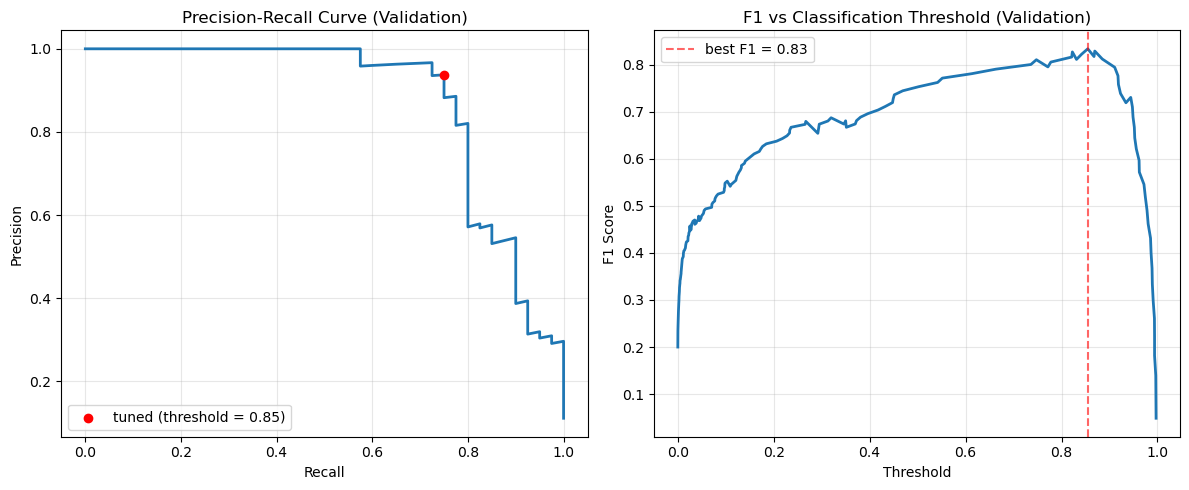


--- Validation Classification Report at Tuned Threshold ---

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       320
           1       0.94      0.75      0.83        40

    accuracy                           0.97       360
   macro avg       0.95      0.87      0.91       360
weighted avg       0.97      0.97      0.97       360



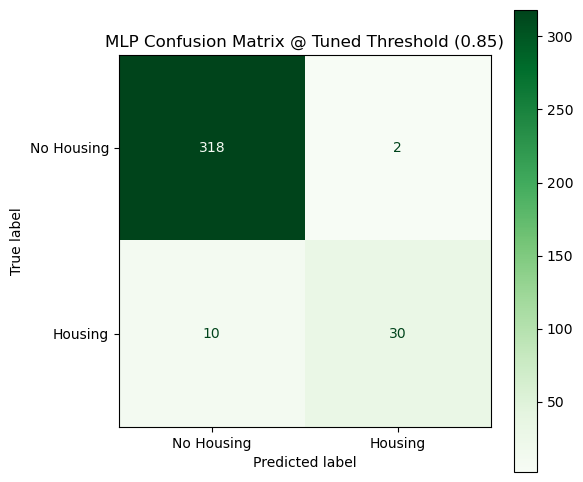

In [78]:
from sklearn.metrics import (
    precision_recall_curve, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
import numpy as np
import matplotlib.pyplot as plt

# Probability of class 1 ("housing mention") on the validation set
val_proba = mlp.predict_proba(X_val_vec)[:, 1]

# Sweep thresholds and pick the one that maximizes F1
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)
# precision_recall_curve returns len(threshold) = len(precisions) - 1
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx = int(np.argmax(f1s))
best_threshold = float(thresholds[best_idx])

print(f"Default threshold 0.50 -> F1 = {f1_score(y_val, (val_proba >= 0.5).astype(int)):.3f}")
print(f"Tuned threshold   {best_threshold:.3f} -> F1 = {f1s[best_idx]:.3f}  "
      f"(precision {precisions[best_idx]:.3f}, recall {recalls[best_idx]:.3f})")

# Plot PR curve and F1 vs threshold for a visual sanity check
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(recalls, precisions, linewidth=2)
ax1.scatter(recalls[best_idx], precisions[best_idx], color='red', zorder=5,
            label=f'tuned (threshold = {best_threshold:.2f})')
ax1.set_xlabel('Recall'); ax1.set_ylabel('Precision')
ax1.set_title('Precision-Recall Curve (Validation)')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(thresholds, f1s, linewidth=2)
ax2.axvline(best_threshold, linestyle='--', color='red', alpha=0.6,
            label=f'best F1 = {f1s[best_idx]:.2f}')
ax2.set_xlabel('Threshold'); ax2.set_ylabel('F1 Score')
ax2.set_title('F1 vs Classification Threshold (Validation)')
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Validation report at the tuned threshold
y_val_tuned = (val_proba >= best_threshold).astype(int)
print("\n--- Validation Classification Report at Tuned Threshold ---\n")
print(classification_report(y_val, y_val_tuned))

cm_tuned = confusion_matrix(y_val, y_val_tuned)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Greens')
plt.title(f'MLP Confusion Matrix @ Tuned Threshold ({best_threshold:.2f})')
plt.show()


### 4. Inference on SMI Cohort (Word2Vec + MLP)
We apply the MLP classifications to the vectors and aggregate manually to admission granularity (`hadm_id`). We use the tuned threshold from before.

In [89]:
# Apply the tuned threshold to SMI sentence probabilities
print(f"Running MLP semantic inference on SMI Sentences (threshold = {best_threshold:.3f})...")
smi_proba = mlp.predict_proba(X_smi_vec)[:, 1]
smi_sentences_df['housing_mlp_sent_proba'] = smi_proba
smi_sentences_df['housing_mlp_sent_pred']  = (smi_proba >= best_threshold).astype(int)

# Aggregate back to hadm_id (If any sentence = 1 -> note is Positive)
mlp_predictions = smi_sentences_df.groupby('hadm_id')['housing_mlp_sent_pred'].max().reset_index()
mlp_predictions.rename(columns={'housing_mlp_sent_pred': 'housing_mlp_pred'}, inplace=True)

# Merge back
if 'housing_mlp_pred' in df.columns:
    df.drop(columns=['housing_mlp_pred'], inplace=True)

df = df.merge(mlp_predictions, on='hadm_id', how='left')
df['housing_mlp_pred'] = df['housing_mlp_pred'].fillna(0).astype(int)

mlp_housing_rate = df['housing_mlp_pred'].mean() * 100

print(f"\nHousing Detection Rate (Keyword/Regex Baseline):  {regex_housing_rate:.2f}%")
print(f"Housing Detection Rate (Word2Vec + MLP Baseline): {mlp_housing_rate:.2f}%")

cross_tab_mlp = pd.crosstab(
    df['housing_mention'].replace({'yes': 'Positive', 'no': 'Negative'}),
    df['housing_mlp_pred'].replace({1: 'Positive', 0: 'Negative'}),
    rownames=['Regex Heuristic'],
    colnames=['MLP Semantic Model']
)
print("\nAgreement Matrix (Regex vs Semantic MLP):")
display(cross_tab_mlp)


Running MLP semantic inference on SMI Sentences (threshold = 0.855)...

Housing Detection Rate (Keyword/Regex Baseline):  50.95%
Housing Detection Rate (Word2Vec + MLP Baseline): 83.19%

Agreement Matrix (Regex vs Semantic MLP):


MLP Semantic Model,Negative,Positive
Regex Heuristic,,
Negative,332,1536
Positive,308,1632


The model predicts most notes as having a housing mention. The crosstab indicates disagreement on the predictions, with the MLP predicting "positive" on many notes where the Keyword Search predicts "negative". Even though we raised the prediction threshold for a housing mention to 0.855, which is much higher than the default value of 0.5, most notes were predicted as having a housing mention.

### 5. View Sentences Flagged as Housing Mentions
Of the discharge notes that were predicted having a housing mention, which sentences were flagged?

In [ ]:
# For each discharge note the MLP flagged as "housing mention",
# pull the specific sentence(s) that the model scored as positive.

positive_hadm_ids = df.loc[df['housing_mlp_pred'] == 1, 'hadm_id']

flagged = smi_sentences_df[
    (smi_sentences_df['hadm_id'].isin(positive_hadm_ids)) &
    (smi_sentences_df['housing_mlp_sent_pred'] == 1)
].copy()

n_notes = flagged['hadm_id'].nunique()
print(f"Flagged sentences total:        {len(flagged):,}")
print(f"Notes contributing those:       {n_notes:,}")
print(f"Avg flagged sentences / note:   {len(flagged) / n_notes:.1f}")
print(f"Max flagged sentences in note:  {flagged.groupby('hadm_id').size().max()}")

print("\n" + "=" * 70)
print("Sample: sentences the MLP flagged as a housing mention")
print("=" * 70)

sample_hadms = flagged['hadm_id'].drop_duplicates().sample(30, random_state=RANDOM_SEED).tolist()

for hadm in sample_hadms:
    sents = flagged.loc[flagged['hadm_id'] == hadm, 'sentence_text'].tolist()
    print(f"\nhadm_id {hadm}  -  {len(sents)} flagged sentence(s)")
    for s in sents[:5]:
        print(f"  - {s}")
    if len(sents) > 5:
        print(f"  ... and {len(sents) - 5} more")

# TODO: remove notes w/ "AXIS" maybe?


# Results Comparison & Interpretation

## Performance summary

| Model | Labeled-val Precision | Labeled-val Recall | Labeled-val F1 | SMI cohort (% flagged) |
|-------|----------------------|--------------------|----------------|------------------------|
| Keyword regex (MS2) | 0.74 | 0.39 | 0.51 | 50.95% |
| TF-IDF + Random Forest | 1.00 | 0.80 | 0.89 | 1.16% |
| Word2Vec + MLP (0.5 threshold) | 0.71 | 0.80 | 0.753 | 96.56% |
| Word2Vec + MLP (F1-tuned threshold) | 0.94 | 0.75 | 0.833 | 83.19% |

## Strengths and weaknesses

### Baseline 1 &mdash; TF-IDF + Random Forest

- &#9989; Fast, interpretable (per-feature importances are individual n-grams), conservative on out-of-distribution inputs.
- &#10060; Vocabulary lookup cannot generalize to the different writing styles in MIMIC-IV. For example, MIMIC-IV can have abbreviations and clinical shorthand.
- &#10060; Sentence length varied in MIMIC-IV while sentence length was more uniform in MIMIC-III

### Baseline 2 &mdash; Word2Vec + MLP

- &#9989; Captures semantic similarity; the custom W2V places `unhoused`, `shelter`, `homeless` near each other in embedding space, so the MLP generalizes beyond exact-match vocabulary.
- &#10060; Only ~160 unique positive training sentences &rArr; the oversampled MLP memorizes them; the default 0.5 threshold over-flags out-of-distribution input (addressed by F1-tuning the threshold on held-out val data in §3b).
- &#10060; The training-vs-inference domain shift (synthetic vs. clinician-written text) is not addressed by either baseline.

## Take-away

Neither bag-of-words nor mean-pooled Word2Vec adequately generalizes from 1,800 labeled sentences to 3,808 full discharge notes. Baseline 1 drastically under-flags the SMI cohort; Baseline 2 requires careful threshold tuning to avoid flagging essentially everything. This confirms our Milestone 2 hypothesis that a **contextual clinical language model** (ClinicalBERT) is needed for the final deliverable.

# Final Model Pipeline

Planned pipeline for the final deliverable:

```
+-------------------------------------------+
|  Training data (labeled)                  |
|  MIMIC-III-Labeled-SDOH: 1,800 sentences  |
|  + weakly-labeled MIMIC-IV sentences      |
|    (keyword-caught, manually reviewed)    |
+--------------------+----------------------+
                     | stratified 80/20 split
                     v
+-------------------------------------------+
|  Fine-tune Bio_ClinicalBERT               |
|  (HuggingFace Transformers)               |
|  - Class-weighted BCE loss                |
|  - Sentence-level inputs                  |
+--------------------+----------------------+
                     |
                     v
+-------------------------------------------+
|  Threshold tuning on validation           |
|  (F1-maximizing, same sweep as Baseline 2 |
|   section 3b)                             |
+--------------------+----------------------+
                     |
                     v
+-------------------------------------------+
|  Inference on SMI cohort (3,808 notes)    |
|  - Reuse sentence preprocessing from      |
|    Baseline 1 section 5                   |
|  - Aggregate sentence preds to note level |
|    via max() -> housing_mention flag      |
+--------------------+----------------------+
                     |
                     v
+-------------------------------------------+
|  Subgroup analysis                        |
|  (race x diagnosis x insurance x gender)  |
|  matching the MS2 breakdowns              |
+-------------------------------------------+
```

## Assumptions & tuning considerations

- **Unit of input:** individual sentences extracted by the Baseline 1 §5 filter. Note-level label is the `max` over sentence predictions. Alternative (future work): use mean sentence probability instead of max.
- **Hyperparameters to tune on the labeled validation set:** model training parameters and sclassification threshold (F1-maximizing).
- **Class imbalance:** handled with class-weighted loss rather than oversampling, so the model sees each positive example once per epoch (avoids the memorization we saw in the MLP baseline).
- **Open assumption:** whether MIMIC-III and MIMIC-IV prose styles are close enough for direct transfer. If the Baseline-1 vocabulary-shift issue persists, we'll augment training with weakly-labeled MIMIC-IV sentences.


# Future Directions & Next Steps

## Next steps before the final submission

1. **Fine-tune Bio_ClinicalBERT** on the combined MIMIC-III labels + MIMIC-IV weak labels, with class-weighted loss and F1-tuned threshold.
2. **Expand the training set** by manually reviewing MIMIC-IV sentences the MS2 regex caught and adding them to the training data (weak supervision).s
3. **Final subgroup analysis** mirroring the MS2 breakdowns (race, insurance, gender, diagnosis) using the best classifier's predictions.

## Challenges & Concerns
1. The MIMIC-III dataset not generalizing well to the MIMIC-IV SMI dataset.
2. The MIMIC-III dataset is unbalanced for housing mention vs. no housing mention.

## Division of responsibilities

- We will collaborate on every step.

## Open questions for the TF

1. Is it acceptable to augment the training set with keyword-caught MIMIC-IV sentences (weak supervision), or should we stick strictly to the MIMIC-III labels for a cleaner comparison?
2. Given sentence-level models still underperform, should we consider a long-input transformer (e.g. ClinicalBERT-long or Longformer) operating on whole notes, accepting the higher compute cost?
